# Exercise: Can an encoder find malaria?

Each image is one blood cell. Some cells are **parasitized** (infected with malaria). Some are **uninfected**.

We used a pretrained encoder (DINOv2) to turn each image into a row of 768 numbers.

## Setup

In [3]:
library('tidymodels')
library('embed')

options(repr.plot.res = 250, repr.plot.height = 3, repr.plot.width = 5)

── Attaching packages ──────────────────────────────────────────────────────────────────────────────────────────────────────── tidymodels 1.4.1 ──
✔ broom        1.0.13     ✔ recipes      1.4.0 
✔ dials        1.4.4      ✔ rsample      1.3.2 
✔ dplyr        1.2.1      ✔ tailor       0.1.0 
✔ ggplot2      4.0.3      ✔ tidyr        1.3.2 
✔ infer        1.1.0      ✔ tune         2.1.0 
✔ modeldata    1.6.0      ✔ workflows    1.3.0 
✔ parsnip      1.6.1      ✔ workflowsets 1.1.1 
✔ purrr        1.2.2      ✔ yardstick    1.4.0 
── Conflicts ─────────────────────────────────────────────────────────────────────────────────────────────────────────── tidymodels_conflicts() ──
✖ tidyr::complete() masks hera::complete()
✖ purrr::discard()  masks scales::discard()
✖ dplyr::filter()   masks stats::filter()
✖ dplyr::lag()      masks stats::lag()
✖ recipes::step()   masks stats::step()
• Learn how to get started at https://www.tidymodels.org/start/


## 1. Load the data

Here are 6 example cells. The top row is parasitized. The bottom row is uninfected.

<img src="https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/malaria_examples/parasitized_C129P90ThinF_IMG_20151004_133921_cell_105.png" width="90"><img src="https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/malaria_examples/parasitized_C189P150ThinF_IMG_20151203_140809_cell_133.png" width="90"> <img src="https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/malaria_examples/parasitized_C52P13thinF_IMG_20150725_130013_cell_194.png" width="90"> <br><img src="https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/malaria_examples/uninfected_C147P108ThinF_IMG_20151115_101156_cell_82.png" width="90"> <img src="https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/malaria_examples/uninfected_C184P145ThinF_IMG_20151203_102405_cell_137.png" width="90"> <img src="https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/malaria_examples/uninfected_C77P38ThinF_IMG_20150601_152941_cell_55.png" width="90">

The encoder already ran. Each row of `malaria` is one image. `e1` to `e768` are its embedding.

In [4]:
malaria <- readr::read_csv('https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/malaria_embeddings.csv.gz', show_col_types = FALSE) |>
    mutate(label = factor(label, levels = c('uninfected', 'parasitized')))

malaria |> select(id, label, e1:e5) |> head()

 [100%] Downloaded 3010429 bytes...
                                                                              

  id                                         label      e1     e2      e3    
1 C184P145ThinF_IMG_20151203_102405_cell_137 uninfected 0.0045  0.0178 0.0393
2 C77P38ThinF_IMG_20150601_152941_cell_55    uninfected 0.0321 -0.0049 0.0702
3 C147P108ThinF_IMG_20151115_101156_cell_82  uninfected 0.0174 -0.0118 0.0692
4 C223ThinF_IMG_20151112_104410_cell_156     uninfected 0.0114 -0.0091 0.0375
5 C92P53ThinF_IMG_20150821_151646_cell_32    uninfected 0.0226  0.0284 0.0138
6 C83P44ThinF_IMG_20150817_134331_cell_194   uninfected 0.0194 -0.0292 0.0345
  e4      e5     
1 -0.0475  0.0563
2 -0.0556 -0.0220
3 -0.0476 -0.0041
4 -0.0590  0.0046
5 -0.0545  0.0345
6 -0.0767  0.0011

In [5]:
malaria |> count(label)

  label       n   
1 uninfected  1000
2 parasitized 1000

## 2. Visualize with UMAP

We cannot plot 768 dimensions at once. **UMAP** squeezes all the dimensions into 2 new columns, `UMAP1` and `UMAP2`. Similar images wil have similar `UMAP1` and `UMAP2` values.

Run the cell. It makes the 2 UMAP columns. (It takes a few seconds.)

In [6]:
set.seed(1)

umap_coords <- recipe(label ~ ., data = select(malaria, -id)) |>
    step_umap(all_predictors(), num_comp = 2) |>
    prep() |>
    bake(new_data = NULL)

umap_coords |> head()

  label      UMAP1     UMAP2     
1 uninfected -3.885077 -0.1045645
2 uninfected -2.033472  1.3991832
3 uninfected -2.757028 -0.8090479
4 uninfected -4.483551 -0.1679591
5 uninfected -2.477914  4.1084366
6 uninfected -2.114880  2.5737996

**Your turn:** plot `UMAP1` against `UMAP2`. Color the points by `label`.

In [14]:
# Chart code goes here
set.seed(1)

pca_coords <- recipe(label ~ ., data = select(malaria, -id)) |>
    step_pca(all_predictors(), num_comp = 2) |>
    prep() |>
    bake(new_data = NULL)

pca_coords |> head()

  label      PC1        PC2       
1 uninfected -0.8333987 0.23484119
2 uninfected -0.8838794 0.07507161
3 uninfected -0.8560391 0.07710921
4 uninfected -0.9037973 0.25315164
5 uninfected -0.7182829 0.11607635
6 uninfected -0.8812922 0.19702196

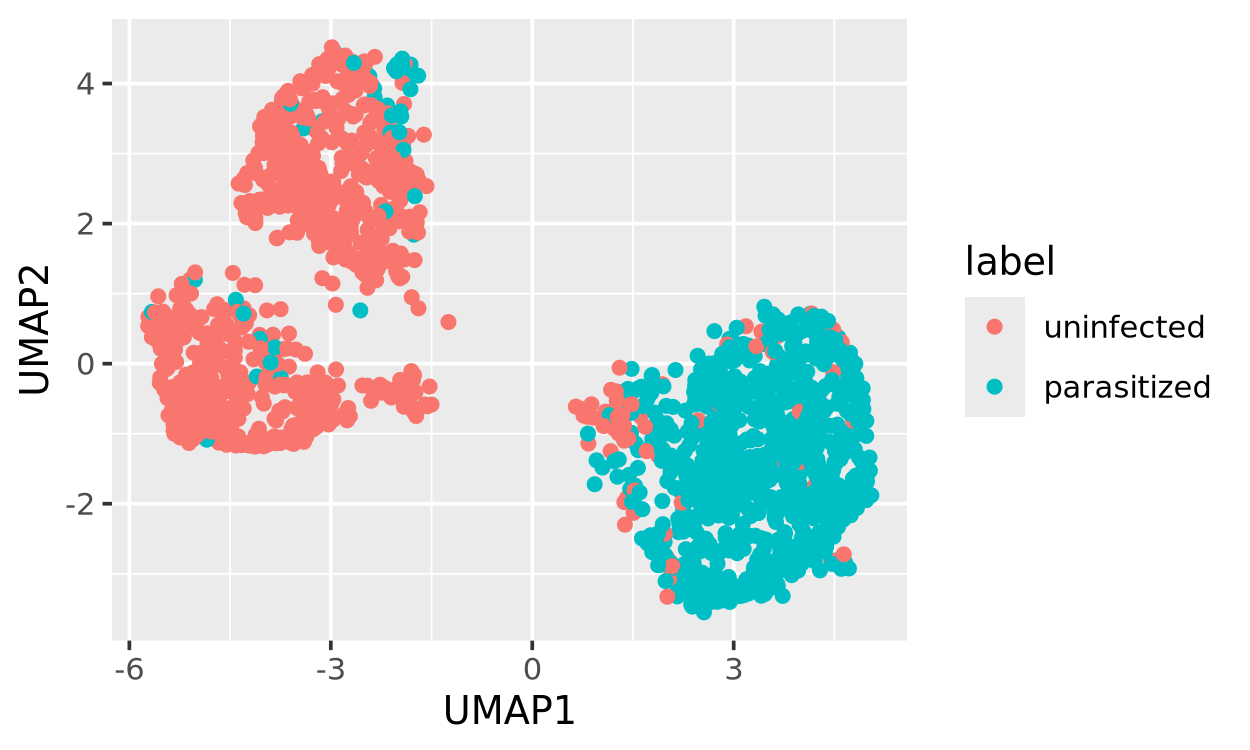

In [15]:
ggplot(umap_coords, aes(x = UMAP1, y = UMAP2, color = label)) + geom_point()

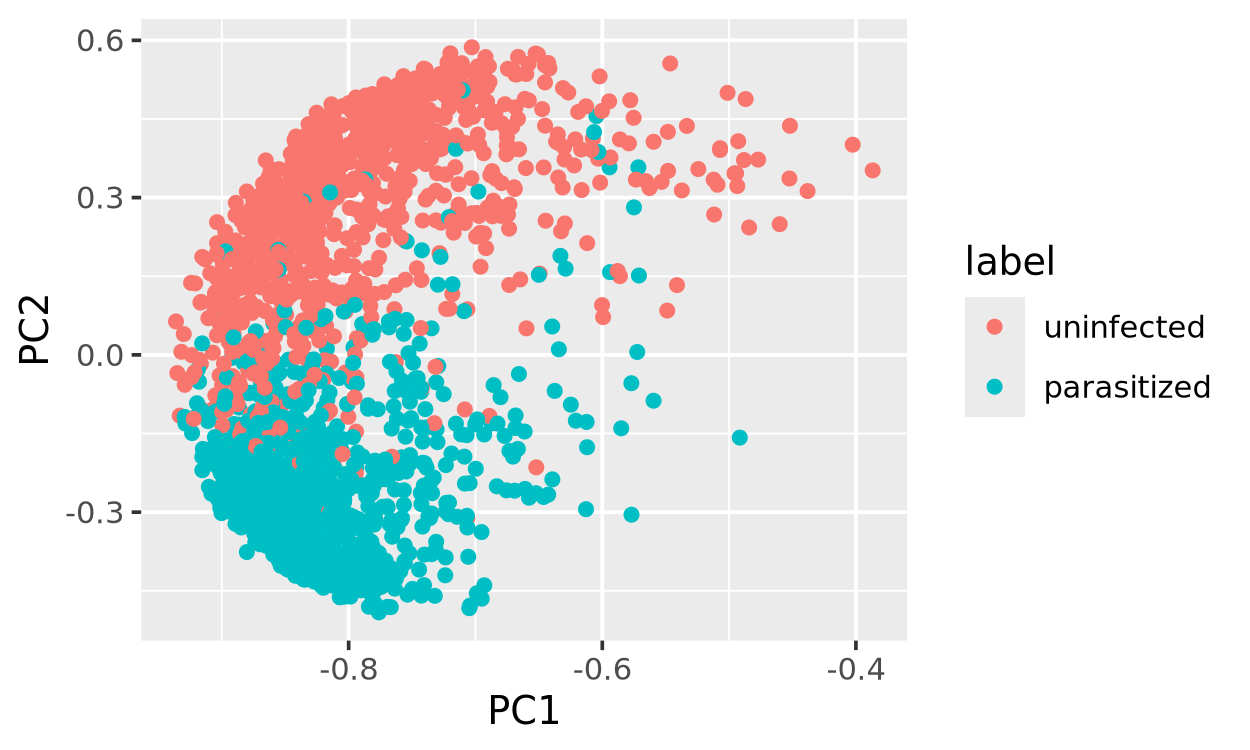

In [16]:
ggplot(pca_coords, aes(x = PC1, y = PC2, color = label)) + geom_point()

**Check:** do the two kinds of cell land in different places?

- Do you see clear groups? Are they perfectly separate?
- Which cells are hard to tell apart?

## 3. Split the data

Run this cell. Do not change it.

- `train`: half of the images. The model learns from these.
- `test`: the other half. The model has never seen these. We measure accuracy here.

In [17]:
set.seed(512)

split <- initial_split(malaria, prop = 0.5, strata = label)
train <- training(split) |> select(-id)
test  <- testing(split)  |> select(-id)

nrow(train)

[1] 1000

## 4. Pick a model

Pick a classifier model that we've worked with before (e.g. random forest). Fit it on `train`. Find the accuracy on `test`.

Options:

- `logistic_reg(penalty = 0.01, mixture = 0) |> set_engine('glmnet')`: logistic regression. We have 768 columns, so it needs a `penalty` (like in lecture 16).
- `rand_forest(trees = 200) |> set_mode('classification') |> set_engine('ranger')`: random forest.
- `mlp(hidden_units = 10, epochs = 500) |> set_mode('classification') |> set_engine('nnet', MaxNWts = 10000)`: neural net.

Use the formula `label ~ .` (all other embeddings columns are predictors).

In [10]:
# Fit your model here
mod = rand_forest(trees = 200) |> set_mode('classification') |> set_engine('ranger')

mod_fit = mod |> fit(label ~ ., data = train)

mod_fit

parsnip model object

Ranger result

Call:
 ranger::ranger(x = maybe_data_frame(x), y = y, num.trees = 200,      num.threads = 1, verbose = FALSE, seed = sample.int(10^5,          1), probability = TRUE) 

Type:                             Probability estimation 
Number of trees:                  200 
Sample size:                      1000 
Number of independent variables:  768 
Mtry:                             27 
Target node size:                 10 
Variable importance mode:         none 
Splitrule:                        gini 
OOB prediction error (Brier s.):  0.04090533 

<details>
<summary>Hint: how do I find the accuracy?</summary>

1. `predict()` gives the predicted class for each test image.
2. `bind_cols()` puts it next to the true `label`.
3. `accuracy()` compares them.

```r
predict(fit, new_data = test) |>
    bind_cols(test) |>
    accuracy(truth = label, estimate = .pred_class)
```

Here `fit` is the name of your fitted model. Use your own name.

</details>

In [18]:
# Accuracy on the test set

predict(mod_fit, new_data = test) |> 
    bind_cols(test) |>
    accuracy(truth = label, estimate = .pred_class)

  .metric  .estimator .estimate
1 accuracy binary     0.936    

**Check:** a good model gets about 0.93 to 0.95 on the test images.

- Why did you pick this model?
- Is the accuracy on `train` higher than on `test`? What does that tell you?

In [19]:
mod = rand_forest(trees = 200) |> set_mode('classification') |> set_engine('ranger')

mod_fit = mod |> fit(label ~ ., data = umap_coords)

mod_fit
     

parsnip model object

Ranger result

Call:
 ranger::ranger(x = maybe_data_frame(x), y = y, num.trees = 200,      num.threads = 1, verbose = FALSE, seed = sample.int(10^5,          1), probability = TRUE) 

Type:                             Probability estimation 
Number of trees:                  200 
Sample size:                      2000 
Number of independent variables:  2 
Mtry:                             1 
Target node size:                 10 
Variable importance mode:         none 
Splitrule:                        gini 
OOB prediction error (Brier s.):  0.04494731 

## 5. Bonus: raw pixels

We also have the raw pixels for the same cells: `malaria_pixels.csv.gz`. That is 32 x 32 = 1,024 columns named `p1` to `p1024`.

Use the same split. Fit the same kind of model on the pixels. How does the test accuracy compare to the embeddings?

In [12]:
pixels <- readr::read_csv('https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/malaria_pixels.csv.gz', show_col_types = FALSE) |>
    mutate(label = factor(label, levels = c('uninfected', 'parasitized')))

# Use the same split: train_pix has the same images as train
train_pix <- pixels |> filter(id %in% training(split)$id) |> select(-id)
test_pix  <- pixels |> filter(id %in% testing(split)$id)  |> select(-id)

# Fit and evaluate here

 [100%] Downloaded 1556446 bytes...
                                                                              

*Your answer:* Which is better for finding malaria: pixels or embeddings? Why?

In [20]:
train_pix <- pixels |> filter(id %in% training(split)$id) |> select(-id)
test_pix  <- pixels |> filter(id %in% testing(split)$id)  |> select(-id)

In [ ]:
mod = rand_forest(trees = 200) |> set_mode('classification') |> set_engine('ranger')

mod_fit = mod |> fit(label ~ ., data = train_pix)

mod_fit

In [ ]:
predict(mod_fit, new_data = test_pix) |> 
    bind_cols(test_pix) |>
    accuracy(truth = label, estimate = .pred_class)